# 07 · Comparación estadística: AR-EGARCH vs. Random Forest

Este notebook compara los dos modelos del proyecto en el pronóstico de la varianza diaria del WTI (proxy de Parkinson):
- **Modelo econométrico:** media constante – EGARCH(1,1,1) con errores t de Student (notebook 03).
- **Modelo de machine learning:** Random Forest con rezagos, k = 16 variables seleccionadas por información mutua (notebook 06).

**Contenido**

0. Configuración
1. Carga de resultados
2. Verificaciones: mismos folds y mismos días
3. Errores de validación por fold
4. Pruebas de hipótesis sobre los 10 folds (Wilcoxon y t pareada)
5. Prueba de Diebold-Mariano sobre los pronósticos diarios
6. Referencia: pronóstico ingenuo
7. Evaluación en el test final (2025 – oct 2026)
8. Ajuste: entrenamiento vs. validación vs. test
9. Guardar resultados
10. Conclusiones

## 0. Configuración

In [ ]:
import sys
import json
import warnings
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.dates as mdates
from matplotlib.patches import Patch


In [2]:

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))


In [3]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti')

In [17]:
from src import config as cfg
from src import ar_garch as ag          # pronostico_egarch
from src import random_forest as rf     # crear_pipeline
from src import comparison as c

In [18]:
importlib.reload(c)

<module 'src.comparison' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\comparison.py'>

In [5]:


PROC = RAIZ / "data" / "processed"
RES_DIR = RAIZ / "results"
FIG_DIR = RAIZ / "figures"
CMP_DIR = RES_DIR / "comparacion"
CMP_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
H_MIN = 1e-6
ALFA = 0.05
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)



## 1. Carga de resultados
Se cargan los errores por fold, los pronósticos diarios de validación de ambos modelos y los mejores hiperparámetros del Random Forest.

In [6]:
FOLDS = pd.read_csv(PROC / "folds.csv", parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

# Errores por fold
err_eg = pd.read_csv(RES_DIR / "egarch_errores_por_fold.csv")
err_rf = pd.read_csv(RES_DIR / "rf_errores_por_fold.csv")

# Pronósticos diarios de validación (indexados por el día objetivo τ)
pron_eg = pd.read_csv(RES_DIR / "egarch_pronosticos_diarios.csv", index_col=0, parse_dates=True)
pron_rf = pd.read_csv(RES_DIR / "rf_pronosticos_diarios.csv", index_col=0, parse_dates=True)

# Hiperparámetros del Random Forest
mejores_rf = json.loads((RES_DIR / "rf_mejores_hiperparametros.json").read_text(encoding="utf-8"))
K_FINAL = mejores_rf["k"]
PARAMS_RF = {p: mejores_rf[p] for p in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]}

print("EGARCH:", err_eg.shape, list(err_eg.columns))
print("RF    :", err_rf.shape, list(err_rf.columns))
print("Pronósticos EGARCH:", pron_eg.shape, "| RF:", pron_rf.shape)
print("Random Forest: k =", K_FINAL, "|", PARAMS_RF)

EGARCH: (10, 13) ['rep', 'fold', 'train_ini', 'train_fin', 'val_ini', 'val_fin', 'n_train', 'n_val', 'mse_train', 'qlike_train', 'mse_egarch', 'qlike_egarch', 'convergencia']
RF    : (10, 10) ['rep', 'fold', 'val_ini', 'val_fin', 'n', 'mse_rf', 'qlike_rf', 'mse_train', 'qlike_train', 'brecha_qlike']
Pronósticos EGARCH: (2512, 4) | RF: (2512, 4)
Random Forest: k = 16 | {'n_estimators': 350, 'max_depth': 7, 'min_samples_leaf': 10, 'max_features': 0.9603717170427477}


## 2. Verificaciones
Para que la comparación sea pareada, ambos modelos deben evaluarse en los mismos 10 folds, en los mismos días y contra el mismo valor observado de Parkinson.

In [7]:
# 1. Los archivos del EGARCH corresponden al modelo EGARCH (no a una versión anterior)
assert {"qlike_egarch", "mse_egarch"}.issubset(err_eg.columns), \
    "egarch_errores_por_fold.csv no tiene las columnas del EGARCH: vuelve a guardarlo en el notebook 03"
assert "h_egarch" in pron_eg.columns, \
    "egarch_pronosticos_diarios.csv no tiene la columna h_egarch: vuelve a guardarlo en el notebook 03"

# 2. Mismos 10 folds en ambos modelos
assert len(err_eg) == len(err_rf) == len(FOLDS) == 10

# 3. Mismos días evaluados en cada fold
claves = ["rep", "fold"]
dias = (pron_eg.reset_index().rename(columns={pron_eg.index.name or "index": "Date"})
        .merge(pron_rf.reset_index().rename(columns={pron_rf.index.name or "index": "Date"}),
               on=["Date", "rep", "fold"], how="outer", suffixes=("_eg", "_rf"), indicator=True))
print(dias["_merge"].value_counts())
assert (dias["_merge"] == "both").all(), "Hay días evaluados por un modelo y no por el otro"

# 4. Ambos modelos se comparan contra el mismo Parkinson
dif_y = (dias["y_eg"] - dias["y_rf"]).abs().max()
print(f"Máxima diferencia en el Parkinson observado entre archivos: {dif_y:.2e}")
assert dif_y < 1e-8

pron = (dias.drop(columns=["_merge", "y_rf"]).rename(columns={"y_eg": "y"})
            .set_index("Date").sort_index())
print("✔ Ambos modelos se evalúan en los mismos", len(pron), "días-fold")

_merge
both          2512
left_only        0
right_only       0
Name: count, dtype: int64
Máxima diferencia en el Parkinson observado entre archivos: 0.00e+00
✔ Ambos modelos se evalúan en los mismos 2512 días-fold


## 3. Errores de validación por fold
La diferencia se define como **EGARCH − Random Forest**: un valor positivo indica que el Random Forest tuvo menor pérdida en ese fold. La QLIKE es la métrica principal mientras que el MSE se reporta como complemento, aunque está dominado por los días extremos de 2020.

In [8]:
tabla_folds = (err_eg[claves + ["val_ini", "val_fin", "qlike_train", "qlike_egarch", "mse_train", "mse_egarch"]]
               .rename(columns={"qlike_train": "qlike_train_egarch", "mse_train": "mse_train_egarch"})
               .merge(err_rf[claves + ["qlike_train", "qlike_rf", "mse_train", "mse_rf"]]
                      .rename(columns={"qlike_train": "qlike_train_rf", "mse_train": "mse_train_rf"}),
                      on=claves))

# Diferencia de pérdida: EGARCH − RF (positiva → el Random Forest tiene menor error)
tabla_folds["dif_qlike"] = tabla_folds["qlike_egarch"] - tabla_folds["qlike_rf"]
tabla_folds["dif_mse"] = tabla_folds["mse_egarch"] - tabla_folds["mse_rf"]
tabla_folds["mejor_qlike"] = np.where(tabla_folds["dif_qlike"] > 0, "Random Forest", "EGARCH")
tabla_folds["etiqueta"] = [f"R{a}·F{b}" for a, b in zip(tabla_folds["rep"], tabla_folds["fold"])]

display(tabla_folds[["etiqueta", "val_ini", "val_fin", "qlike_egarch", "qlike_rf", "dif_qlike",
                     "mse_egarch", "mse_rf", "dif_mse", "mejor_qlike"]].round(4))

resumen_val = pd.DataFrame({
    "QLIKE media": [tabla_folds["qlike_egarch"].mean(), tabla_folds["qlike_rf"].mean()],
    "QLIKE desv.": [tabla_folds["qlike_egarch"].std(), tabla_folds["qlike_rf"].std()],
    "MSE media":   [tabla_folds["mse_egarch"].mean(), tabla_folds["mse_rf"].mean()],
    "MSE mediana": [tabla_folds["mse_egarch"].median(), tabla_folds["mse_rf"].median()],
    "folds con menor QLIKE": [(tabla_folds["dif_qlike"] < 0).sum(), (tabla_folds["dif_qlike"] > 0).sum()],
}, index=["AR-EGARCH", "Random Forest"])
display(resumen_val.round(4))

,etiqueta,val_ini,val_fin,qlike_egarch,qlike_rf,dif_qlike,mse_egarch,mse_rf,dif_mse,mejor_qlike
0,R1·F1,2020-01-01,2020-12-31,3.5860,3.9612,-0.3752,4700.1981,6273.1761,-1572.9780,EGARCH
1,R1·F2,2021-01-01,2021-12-31,2.6876,2.5321,0.1555,49.9899,107.8630,-57.8731,Random Forest
2,R1·F3,2022-01-01,2022-12-31,3.4545,3.1929,0.2616,157.4690,206.2362,-48.7672,Random Forest
3,R1·F4,2023-01-01,2023-12-31,2.4879,2.4509,0.0370,17.2718,15.4085,1.8633,Random Forest
4,R1·F5,2024-01-01,2024-12-31,2.1094,2.0767,0.0327,8.6837,6.5271,2.1566,Random Forest
5,R2·F1,2019-07-01,2020-06-30,3.4082,3.7994,-0.3912,4714.4630,6269.4160,-1554.9530,EGARCH
6,R2·F2,2020-07-01,2021-06-30,2.6255,2.5346,0.0909,29.8683,29.7900,0.0783,Random Forest
7,R2·F3,2021-07-01,2022-06-30,3.2840,2.9481,0.3359,170.4871,273.6881,-103.2010,Random Forest
8,R2·F4,2022-07-01,2023-06-30,2.8912,2.8952,-0.0039,36.5540,56.7975,-20.2435,EGARCH
9,R2·F5,2023-07-01,2024-06-30,2.1229,2.0965,0.0263,6.6370,5.2369,1.4000,Random Forest


,QLIKE media,QLIKE desv.,MSE media,MSE mediana,folds con menor QLIKE
AR-EGARCH,2.8657,0.5468,989.1622,43.2719,3
Random Forest,2.8487,0.6490,1324.4140,82.3302,7


In [12]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch

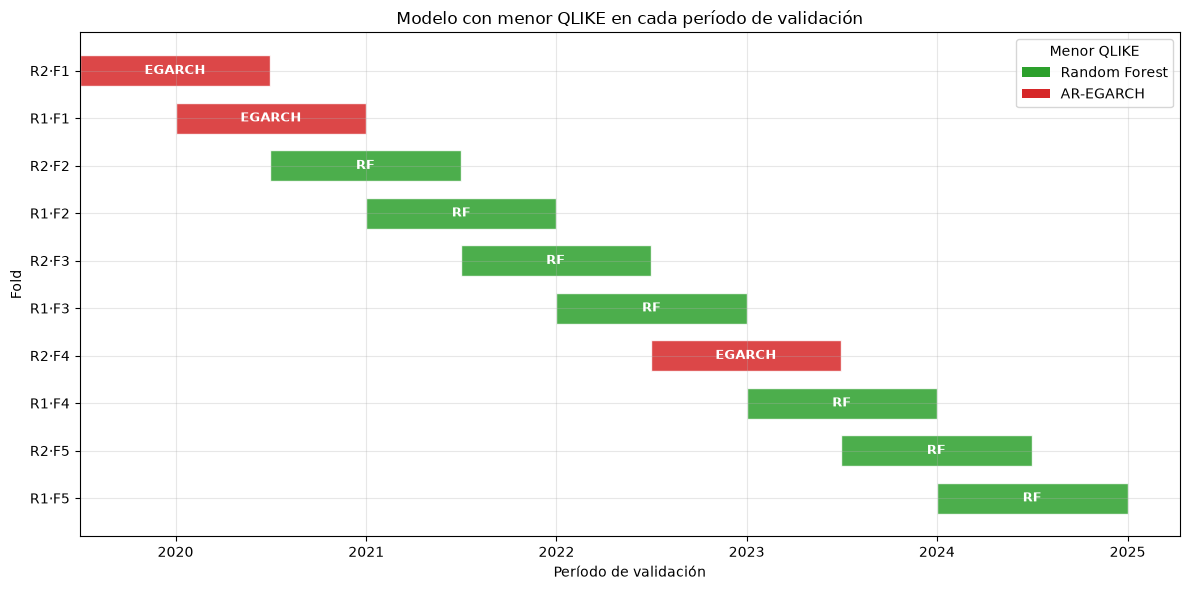

In [13]:
periodos = tabla_folds.copy()
periodos["val_ini"] = pd.to_datetime(periodos["val_ini"])
periodos["val_fin"] = pd.to_datetime(periodos["val_fin"])
periodos = periodos.sort_values(
    ["val_ini", "rep", "fold"]
).reset_index(drop=True)

colores = {
    "Random Forest": "tab:green",
    "EGARCH": "tab:red",
}

fig, ax = plt.subplots(figsize=(12, 6))

for posicion, fila in periodos.iterrows():
    inicio = mdates.date2num(fila["val_ini"])
    fin = mdates.date2num(fila["val_fin"] + pd.Timedelta(days=1))
    modelo = fila["mejor_qlike"]
    nombre_corto = "RF" if modelo == "Random Forest" else "EGARCH"

    ax.barh(
        posicion,
        fin - inicio,
        left=inicio,
        height=0.65,
        color=colores[modelo],
        alpha=0.85,
        edgecolor="white",
    )
    ax.text(
        inicio + (fin - inicio) / 2,
        posicion,
        nombre_corto,
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )

ax.set_yticks(range(len(periodos)))
ax.set_yticklabels(periodos["etiqueta"])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_xlabel("Período de validación")
ax.set_ylabel("Fold")
ax.set_title("Modelo con menor QLIKE en cada período de validación")
ax.legend(
    handles=[
        Patch(facecolor=colores["Random Forest"], label="Random Forest"),
        Patch(facecolor=colores["EGARCH"], label="AR-EGARCH"),
    ],
    title="Menor QLIKE",
)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Random Forest tiene un QLIKE promedio ligeramente menor que AR-EGARCH (2.8487 frente a 2.8657) y obtiene el menor QLIKE en 7 de los 10 folds. Su ventaja aparece en la mayoría de los períodos evaluados, aunque AR-EGARCH supera al Random Forest en tres folds, incluidos dos que abarcan 2020. La diferencia promedio de QLIKE es pequeña y Random Forest presenta mayor variabilidad entre folds.

En cambio, AR-EGARCH obtiene menores valores de MSE, tanto en promedio como en mediana. Esta diferencia se relaciona especialmente con los errores extremos de algunos períodos, que pesan mucho en el MSE. Por tanto, el modelo preferido depende de la métrica: según QLIKE, Random Forest muestra una ventaja leve; según MSE, AR-EGARCH.

La línea de tiempo muestra que su ventaja se concentra en la mayoría de los períodos desde 2021 hasta 2024. AR-EGARCH obtiene mejor resultado en los folds que incluyen principalmente 2020 y en el período julio de 2022–junio de 2023.

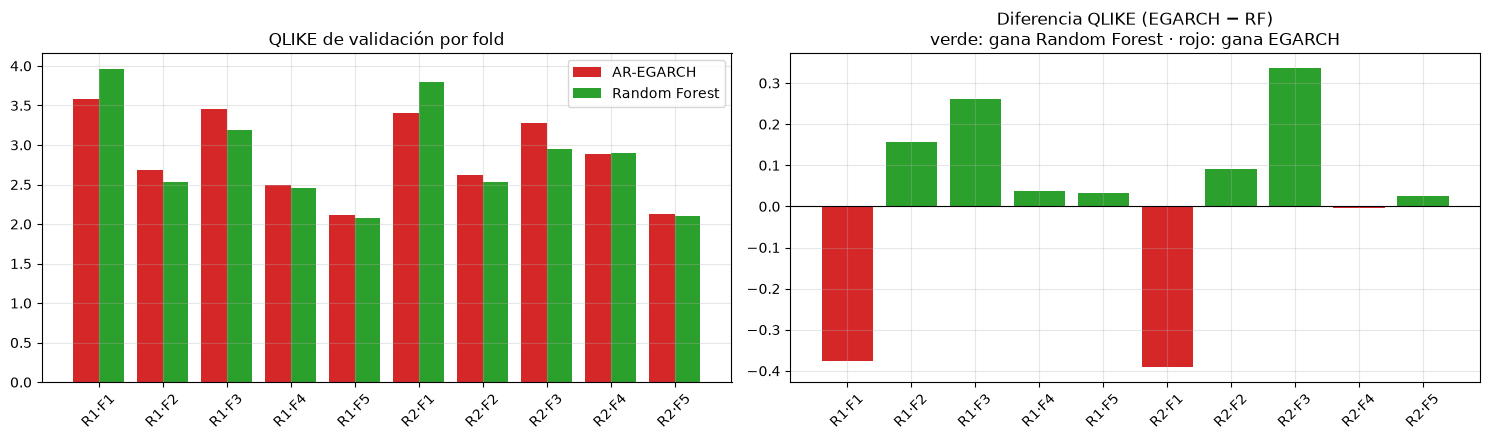

In [9]:
x = np.arange(len(tabla_folds))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].bar(x - 0.2, tabla_folds["qlike_egarch"], 0.4, label="AR-EGARCH", color="tab:red")
ax[0].bar(x + 0.2, tabla_folds["qlike_rf"], 0.4, label="Random Forest", color="tab:green")
ax[0].set_xticks(x, tabla_folds["etiqueta"], rotation=45)
ax[0].set_title("QLIKE de validación por fold"); ax[0].legend()

colores = np.where(tabla_folds["dif_qlike"] > 0, "tab:green", "tab:red")
ax[1].bar(x, tabla_folds["dif_qlike"], color=colores)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xticks(x, tabla_folds["etiqueta"], rotation=45)
ax[1].set_title("Diferencia QLIKE (EGARCH − RF)\nverde: gana Random Forest · rojo: gana EGARCH")

plt.tight_layout(); plt.savefig(FIG_DIR / "07_qlike_por_fold.png", dpi=150); plt.show()

El gráfico compara el QLIKE de validación de ambos modelos en cada fold. En **7 de los 10 folds**, Random Forest tiene menor QLIKE; en los otros tres, gana AR-EGARCH. La diferencia más marcada a favor de Random Forest se observa en **R2·F3**, mientras que AR-EGARCH presenta su mayor ventaja en **R2·F1**. En **R2·F4**, la diferencia es casi nula.

En conjunto, los resultados favorecen ligeramente a Random Forest según QLIKE, pero la ventaja cambia según el período y es pequeña en algunos folds. El gráfico muestra dónde gana cada modelo, pero no permite determinar si la diferencia general es estadísticamente significativa.

## 4. Pruebas de hipótesis sobre los 10 folds

Se comparan las pérdidas de validación de ambos modelos en los mismos 10 folds de Time Series Cross-Validation (2 repeticiones × 5 folds).

- $H_0$: ambos modelos tienen la misma pérdida de validación (la mediana de las diferencias es 0).
- $H_1$: las pérdidas son distintas.

**Wilcoxon de rangos con signo** es la prueba principal: no supone normalidad, adecuado con solo 10 pares. La **t pareada** se reporta como complemento, junto con la prueba de Shapiro-Wilk sobre las diferencias para revisar su supuesto de normalidad.

Limitación: los folds de las dos repeticiones se superponen en el tiempo (comparten medio año de validación) y sus entrenamientos son anidados, por lo que los 10 pares no son completamente independientes. Por eso los resultados se complementan con la prueba de Diebold-Mariano.

In [ ]:
pruebas_folds = pd.DataFrame([
    c.pruebas_pareadas(tabla_folds["qlike_egarch"], tabla_folds["qlike_rf"], "QLIKE"),
    c.pruebas_pareadas(tabla_folds["mse_egarch"], tabla_folds["mse_rf"], "MSE"),
]).set_index("métrica")
pruebas_folds["¿diferencia significativa (Wilcoxon, 5%)?"] = pruebas_folds["Wilcoxon p"] < ALFA
display(pruebas_folds.round(4))

# Normalidad de las diferencias (supuesto de la t pareada)
sw = stats.shapiro(tabla_folds["dif_qlike"])
print(f"Shapiro-Wilk de las diferencias de QLIKE: W = {sw.statistic:.3f}, p = {sw.pvalue:.4f}")

,media EGARCH,media RF,diferencia media (EGARCH − RF),folds con RF mejor,Wilcoxon W,Wilcoxon p,t pareada,t p,"¿diferencia significativa (Wilcoxon, 5%)?"
métrica,,,,,,,,,
QLIKE,2.8657,2.8487,0.0170,7,20.0,0.4922,0.2258,0.8264,False
MSE,989.1622,1324.4140,-335.2518,4,10.0,0.0840,-1.6348,0.1365,False


Shapiro-Wilk de las diferencias de QLIKE: W = 0.881, p = 0.1345


La prueba pareada **no detecta diferencias estadísticamente significativas (pvalor $\geq$ 0.05 , no se rechaza $H_{0}$)** entre AR-EGARCH y Random Forest al nivel del 5 %, ni con QLIKE ni con MSE. 

Para QLIKE, Random Forest tuvo menor pérdida en 7 de los 10 folds y una media ligeramente inferior (2.8487 frente a 2.8657), pero la diferencia no fue significativa según Wilcoxon (*p* = 0.4922; *p* de la *t* pareada = 0.8264). 

Para MSE, la media favorece a AR-EGARCH (989.16 frente a 1324.41), aunque tampoco se alcanzó significancia estadística (Wilcoxon *p* = 0.0840; *t* pareada *p* = 0.1365).

Por tanto, estos resultados no aportan evidencia suficiente para afirmar que uno de los modelos sea superior al otro en los folds evaluados. El test de Shapiro-Wilk para las diferencias de QLIKE (*p* = 0.1345) no detecta una desviación significativa de la normalidad, aunque esto no demuestra que las diferencias sean normales. Además, como algunos folds se solapan en el tiempo, los resultados de la prueba pareada deben interpretarse con cautela.

En conclusión, no se rechaza la hipótesis nula de que no hay diferencia en las pérdidas de los modelos y esto significa que los datos no dan evidencia suficiente para afirmar que las pérdidas sean distintas y tampoco demuestra que sean exactamente iguales.

## 5. Prueba de Diebold-Mariano

Compara la precisión de los pronósticos **día a día**. Para cada día objetivo se calcula $d_\tau = L_{\text{EGARCH},\tau} - L_{\text{RF},\tau}$, y se contrasta $H_0: E[d_\tau] = 0$ (igual precisión). Como las diferencias de pérdida diarias están autocorrelacionadas (la volatilidad es persistente), la varianza de la media se estima con el método de Newey-West (HAC).

Se aplica por separado a cada repetición para no contar dos veces los días que se repiten entre repeticiones. La repetición 1 cubre 2020–2024 sin solapamientos.

In [19]:
L_eg = c.perdidas(pron["y"], pron["h_egarch"]).set_index(pron.index)
L_rf = c.perdidas(pron["y"], pron["h_rf"]).set_index(pron.index)

filas_dm = []
for nombre, filtro in [("Repetición 1 (2020–2024, sin días repetidos)", pron["rep"] == 1),
                       ("Repetición 2 (jul 2019 – jun 2024)", pron["rep"] == 2)]:
    for met in ["qlike", "mse"]:
        r_dm = c.diebold_mariano(L_eg.loc[filtro.values, met], L_rf.loc[filtro.values, met])
        filas_dm.append({"muestra": nombre, "métrica": met.upper(), **r_dm})

dm_val = pd.DataFrame(filas_dm)
dm_val["¿significativo (5%)?"] = dm_val["p-valor"] < ALFA
dm_val["modelo con menor pérdida"] = np.where(dm_val["diferencia media"] > 0, "Random Forest", "AR-EGARCH")
display(dm_val.round(4))

,muestra,métrica,T,rezagos HAC,diferencia media,DM,p-valor,¿significativo (5%)?,modelo con menor pérdida
0,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,1256,7,0.0224,0.3535,0.7238,False,Random Forest
1,"Repetición 1 (2020–2024, sin días repetidos)",MSE,1256,7,-334.8987,-1.6847,0.0923,False,AR-EGARCH
2,Repetición 2 (jul 2019 – jun 2024),QLIKE,1256,7,0.0119,0.1848,0.8534,False,Random Forest
3,Repetición 2 (jul 2019 – jun 2024),MSE,1256,7,-335.2000,-1.7047,0.0885,False,AR-EGARCH


En la prueba de Diebold–Mariano, ninguno de los resultados es estadísticamente significativo al 5 %: todos los p-valores son mayores que 0.05.

En ambas repeticiones, la diferencia media de QLIKE (EGARCH − Random Forest) es positiva, así que el promedio favorece ligeramente a Random Forest. Para MSE, la diferencia es negativa y favorece a AR-EGARCH. Sin embargo, como los resultados no son significativos (p entre 0.0885 y 0.8534), no hay evidencia suficiente para concluir que un modelo tenga mayor precisión predictiva que el otro en estas muestras.

## 6. Referencia: pronóstico ingenuo
Para saber si los errores de ambos modelos son "buenos", se comparan con un pronóstico simple: la varianza de mañana es el promedio de Parkinson de los últimos 21 días (`park_media_21`). Un modelo que no supera esta referencia estaría subajustado.

In [21]:
X_full = pd.read_csv(PROC / "fe_features_X.csv", index_col=0, parse_dates=True)
pron["h_ingenuo"] = X_full["park_media_21"].reindex(pron.index).values

filas = []
for (rep, fold), g in pron.groupby(["rep", "fold"]):
    fila = {"rep": rep, "fold": fold}
    for col, nom in [("h_egarch", "egarch"), ("h_rf", "rf"), ("h_ingenuo", "ingenuo")]:
        L = c.perdidas(g["y"], g[col])
        fila[f"qlike_{nom}"] = L["qlike"].mean()
        fila[f"mse_{nom}"] = L["mse"].mean()
    filas.append(fila)
con_ingenuo = pd.DataFrame(filas)
display(con_ingenuo[["qlike_egarch", "qlike_rf", "qlike_ingenuo"]].agg(["mean", "std"]).round(4).T)

,mean,std
qlike_egarch,2.8657,0.5468
qlike_rf,2.8487,0.6490
qlike_ingenuo,2.8290,0.5579


In [22]:
L_eg = c.perdidas(pron["y"], pron["h_egarch"]).set_index(pron.index)
L_rf = c.perdidas(pron["y"], pron["h_rf"]).set_index(pron.index)
L_ing = c.perdidas(pron["y"], pron["h_ingenuo"]).set_index(pron.index)

comparaciones = [
    ("AR-EGARCH", L_eg, "Random Forest", L_rf),
    ("AR-EGARCH", L_eg, "Ingenuo", L_ing),
    ("Random Forest", L_rf, "Ingenuo", L_ing),
]

muestras = [
    ("Repetición 1 (2020–2024, sin días repetidos)", pron["rep"] == 1),
    ("Repetición 2 (jul 2019 – jun 2024)", pron["rep"] == 2),
]

filas_dm = []

for nombre_muestra, filtro in muestras:
    for met in ["qlike", "mse"]:
        for nombre_a, perdida_a, nombre_b, perdida_b in comparaciones:
            r_dm = c.diebold_mariano(
                perdida_a.loc[filtro.values, met],
                perdida_b.loc[filtro.values, met],
            )

            diferencia = r_dm["diferencia media"]
            if diferencia > 0:
                mejor = nombre_b
            elif diferencia < 0:
                mejor = nombre_a
            else:
                mejor = "Empate"

            filas_dm.append({
                "muestra": nombre_muestra,
                "métrica": met.upper(),
                "comparación": f"{nombre_a} − {nombre_b}",
                **r_dm,
                "modelo con menor pérdida": mejor,
            })

dm_val = pd.DataFrame(filas_dm)
dm_val["¿significativo (5%)?"] = dm_val["p-valor"] < ALFA

display(
    dm_val[
        [
            "muestra",
            "métrica",
            "comparación",
            "T",
            "diferencia media",
            "DM",
            "p-valor",
            "¿significativo (5%)?",
            "modelo con menor pérdida",
        ]
    ].round(4)
)

,muestra,métrica,comparación,T,diferencia media,DM,p-valor,¿significativo (5%)?,modelo con menor pérdida
0,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,AR-EGARCH − Random Forest,1256,0.0224,0.3535,0.7238,False,Random Forest
1,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,AR-EGARCH − Ingenuo,1256,0.0391,1.0362,0.3003,False,Ingenuo
2,"Repetición 1 (2020–2024, sin días repetidos)",QLIKE,Random Forest − Ingenuo,1256,0.0167,0.3118,0.7552,False,Ingenuo
3,"Repetición 1 (2020–2024, sin días repetidos)",MSE,AR-EGARCH − Random Forest,1256,-334.8987,-1.6847,0.0923,False,AR-EGARCH
4,"Repetición 1 (2020–2024, sin días repetidos)",MSE,AR-EGARCH − Ingenuo,1256,-141.9415,-1.1204,0.2628,False,AR-EGARCH
5,"Repetición 1 (2020–2024, sin días repetidos)",MSE,Random Forest − Ingenuo,1256,192.9573,0.7306,0.4652,False,Ingenuo
6,Repetición 2 (jul 2019 – jun 2024),QLIKE,AR-EGARCH − Random Forest,1256,0.0119,0.1848,0.8534,False,Random Forest
7,Repetición 2 (jul 2019 – jun 2024),QLIKE,AR-EGARCH − Ingenuo,1256,0.0346,0.9010,0.3678,False,Ingenuo
8,Repetición 2 (jul 2019 – jun 2024),QLIKE,Random Forest − Ingenuo,1256,0.0227,0.4203,0.6744,False,Ingenuo
9,Repetición 2 (jul 2019 – jun 2024),MSE,AR-EGARCH − Random Forest,1256,-335.2000,-1.7047,0.0885,False,AR-EGARCH


Aunque las pérdidas medias sugieren algunas diferencias entre modelos, la prueba de Diebold–Mariano no encuentra diferencias significativas en precisión predictiva al nivel del 5 % entre ningún par de modelos, en ninguna repetición ni con QLIKE ni con MSE: todos los p-valores son mayores que 0.05. Por tanto, no se rechaza la hipótesis nula de igual precisión predictiva.

## 7. Evaluación en el test final (2025 – oct 2026)

Ambos modelos ya están definidos: el EGARCH por el diagnóstico (notebook 03) y el Random Forest por Optuna (notebook 06). Se estiman **una sola vez con todo el periodo de desarrollo (2010–2024)** y se evalúan en el test, que no se usó en ninguna decisión previa.
- **AR-EGARCH:** parámetros estimados con el desarrollo; pronóstico a un paso para cada día del test con parámetros fijos.
- **Random Forest:** `pipeline.fit(X_desarrollo, y_desarrollo)` y `pipeline.predict(X_test)`.

In [ ]:
TEST_INI, TEST_FIN = pd.Timestamp(cfg.TEST_INI), pd.Timestamp(cfg.TEST_FIN)
DEV_FIN = pd.Timestamp(cfg.DEV_FIN)

# Retornos y Parkinson de toda la serie (desarrollo + test)
ret_dev = pd.read_csv(PROC / "train_validation.csv", index_col=0, parse_dates=True)
ret_test = pd.read_csv(PROC / "test.csv", index_col=0, parse_dates=True)      # ajusta el nombre si es otro
base_ret = pd.concat([ret_dev, ret_test]).sort_index()
base_ret = base_ret[~base_ret.index.duplicated(keep="first")]
r_full, park_full = base_ret["WTI"], base_ret["WTI_park"]

print(f"Serie completa: {base_ret.index.min().date()} → {base_ret.index.max().date()} ({len(base_ret)} días)")
print(f"Test final: {ret_test.index.min().date()} → {ret_test.index.max().date()} ({len(ret_test)} días)")

Tus features guardadas terminan en 2024, así que aquí se recalculan para toda la serie con la misma extracción (20 rezagos y ventanas de 5, 21 y 63 días, que dan tus 67 columnas). La verificación comprueba que coinciden con fe_features_X.csv en el desarrollo.

In [ ]:
def construir_features(base_ret, col_r="WTI", col_park="WTI_park", n_lags=20, ventanas=(5, 21, 63)):
    # Misma extracción de rezagos del notebook de feature extraction (fila τ: información hasta τ-1)
    r = base_ret[col_r]
    park = base_ret[col_park]
    X = pd.DataFrame(index=base_ret.index)
    for k in range(1, n_lags + 1):
        X[f"r2_lag{k}"] = (r**2).shift(k)
        X[f"absr_lag{k}"] = r.abs().shift(k)
        X[f"park_lag{k}"] = park.shift(k)
    for w in ventanas:
        X[f"vol_r_{w}"] = r.rolling(w).std().shift(1)
        X[f"park_media_{w}"] = park.rolling(w).mean().shift(1)
    X["r_lag1"] = r.shift(1)
    y = park.rename("y")
    datos = pd.concat([X, y], axis=1).dropna()
    return datos.drop(columns="y"), datos["y"]


X_all, y_all = construir_features(base_ret)
X_all = X_all[X_full.columns]                                     # mismo orden de columnas

# Verificación: en el desarrollo, las features recalculadas coinciden con las guardadas
comunes = X_full.index.intersection(X_all.index)
dif_max = (X_all.loc[comunes] - X_full.loc[comunes]).abs().max().max()
print(f"Máxima diferencia con fe_features_X.csv en el desarrollo: {dif_max:.2e}")
assert dif_max < 1e-8, "Las features recalculadas no coinciden: revisa n_lags/ventanas con el notebook 04"

X_dev, y_dev = X_all.loc[:DEV_FIN], y_all.loc[:DEV_FIN]
X_test, y_test = X_all.loc[TEST_INI:TEST_FIN], y_all.loc[TEST_INI:TEST_FIN]
print(f"Desarrollo: {X_dev.shape} | Test: {X_test.shape}")

In [ ]:
# AR-EGARCH: parámetros estimados con todo el desarrollo; pronóstico a un paso en el test
ESPEC3 = dict(mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="t")    # modelo seleccionado en el notebook 03

h_eg_test, res_eg_dev = ag.pronostico_egarch(r_full, DEV_FIN, TEST_INI, TEST_FIN, espec=ESPEC3)
h_eg_dev = pd.Series(np.asarray(res_eg_dev.conditional_volatility),
                     index=r_full.loc[:DEV_FIN].index) ** 2                 # dentro de muestra (desarrollo)

display(res_eg_dev.params.round(4).to_frame("parámetros con todo el desarrollo"))

In [ ]:
# Random Forest: pipeline ajustado con todo el desarrollo y los mejores hiperparámetros
pipe_final = rf.crear_pipeline(K_FINAL, **PARAMS_RF)
pipe_final.fit(X_dev, y_dev)                                       # .fit solo con el desarrollo

h_rf_dev = pd.Series(pipe_final.predict(X_dev), index=X_dev.index)            # dentro de muestra
h_rf_test = pd.Series(np.clip(pipe_final.predict(X_test), H_MIN, None), index=X_test.index)

vars_final = X_dev.columns[pipe_final.named_steps["seleccion"].get_support()].tolist()
print("Variables seleccionadas con todo el desarrollo:", vars_final)

In [ ]:
test = pd.DataFrame({"y": y_test, "h_egarch": h_eg_test, "h_rf": h_rf_test,
                     "h_ingenuo": X_test["park_media_21"]}).dropna()
print(f"Días del test evaluados por los tres: {len(test)} | {test.index.min().date()} → {test.index.max().date()}")

errores_test = pd.DataFrame({
    nom: perdidas(test["y"], test[col]).mean()
    for nom, col in [("AR-EGARCH", "h_egarch"), ("Random Forest", "h_rf"), ("Ingenuo (media 21 días)", "h_ingenuo")]
}).T
display(errores_test.round(4))

L_eg_t, L_rf_t = perdidas(test["y"], test["h_egarch"]), perdidas(test["y"], test["h_rf"])
dm_test = pd.DataFrame([{"métrica": m.upper(), **diebold_mariano(L_eg_t[m], L_rf_t[m])} for m in ["qlike", "mse"]])
dm_test["¿significativo (5%)?"] = dm_test["p-valor"] < ALFA
dm_test["modelo con menor pérdida"] = np.where(dm_test["diferencia media"] > 0, "Random Forest", "AR-EGARCH")
display(dm_test.round(4))

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
ax[0].plot(test.index, test["y"], lw=0.6, color="grey", alpha=0.7, label="Parkinson")
ax[0].plot(test.index, test["h_egarch"], lw=1.3, color="tab:red", label="AR-EGARCH")
ax[0].plot(test.index, test["h_rf"], lw=1.3, color="tab:green", label="Random Forest")
ax[0].set_title("Test final: varianza pronosticada vs Parkinson"); ax[0].set_ylabel("%²"); ax[0].legend()

d_test = (L_eg_t["qlike"] - L_rf_t["qlike"]).values
ax[1].plot(test.index, np.cumsum(d_test), color="tab:blue")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Diferencia acumulada de QLIKE en el test (EGARCH − RF)")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_test_final.png", dpi=150); plt.show()

## 8. Ajuste: entrenamiento vs. validación vs. test
- **Train ≈ validación ≈ test:** buen ajuste y buena generalización.
- **Train mucho menor que validación:** sobreajuste.
- **Errores similares o peores que el pronóstico ingenuo:** subajuste.
- **Validación ≈ test:** la validación cruzada fue un buen estimador del desempeño real.

El error de train corresponde a los modelos estimados con todo el desarrollo (los mismos que se evalúan en el test).

In [ ]:
d_eg = pd.concat({"y": park_full, "h": h_eg_dev}, axis=1).dropna()
d_rf = pd.concat({"y": y_dev, "h": h_rf_dev}, axis=1).dropna()
d_in = pd.concat({"y": y_dev, "h": X_dev["park_media_21"]}, axis=1).dropna()

def fila_ajuste(nombre, L_train, val_qlike, val_mse, L_test):
    return {"modelo": nombre,
            "QLIKE train": L_train["qlike"].mean(),
            "QLIKE validación (media 10 folds)": val_qlike.mean(),
            "QLIKE validación (desv.)": val_qlike.std(),
            "QLIKE test": L_test["qlike"].mean(),
            "MSE train": L_train["mse"].mean(),
            "MSE validación (media)": val_mse.mean(),
            "MSE test": L_test["mse"].mean()}

ajuste = pd.DataFrame([
    fila_ajuste("AR-EGARCH", perdidas(d_eg["y"], d_eg["h"]),
                tabla_folds["qlike_egarch"], tabla_folds["mse_egarch"], L_eg_t),
    fila_ajuste("Random Forest", perdidas(d_rf["y"], d_rf["h"]),
                tabla_folds["qlike_rf"], tabla_folds["mse_rf"], L_rf_t),
    fila_ajuste("Ingenuo (media 21 días)", perdidas(d_in["y"], d_in["h"]),
                con_ingenuo["qlike_ingenuo"], con_ingenuo["mse_ingenuo"],
                perdidas(test["y"], test["h_ingenuo"])),
]).set_index("modelo")
ajuste["brecha validación − train"] = ajuste["QLIKE validación (media 10 folds)"] - ajuste["QLIKE train"]
ajuste["brecha test − validación"] = ajuste["QLIKE test"] - ajuste["QLIKE validación (media 10 folds)"]
display(ajuste.round(4))

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
partes = ["QLIKE train", "QLIKE validación (media 10 folds)", "QLIKE test"]
for modelo, color in zip(ajuste.index, ["tab:red", "tab:green", "tab:grey"]):
    ax.plot(["Train", "Validación", "Test"], ajuste.loc[modelo, partes], "o-", color=color, label=modelo)
ax.set_ylabel("QLIKE"); ax.set_title("QLIKE en entrenamiento, validación y test final")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "07_train_val_test.png", dpi=150); plt.show()

## 9. Guardar

In [ ]:
tabla_folds.to_csv(CMP_DIR / "comparacion_por_fold.csv", index=False)
resumen_val.to_csv(CMP_DIR / "resumen_validacion.csv")
pruebas_folds.to_csv(CMP_DIR / "pruebas_wilcoxon_t.csv")
dm_val.to_csv(CMP_DIR / "diebold_mariano_validacion.csv", index=False)
con_ingenuo.to_csv(CMP_DIR / "comparacion_con_ingenuo.csv", index=False)
test.to_csv(CMP_DIR / "pronosticos_test.csv")
errores_test.to_csv(CMP_DIR / "errores_test.csv")
dm_test.to_csv(CMP_DIR / "diebold_mariano_test.csv", index=False)
ajuste.to_csv(CMP_DIR / "train_validacion_test.csv")
print("Resultados guardados en", CMP_DIR)

## 10. Conclusiones

## 10. Conclusiones
_Completar con los resultados:_
1. **Validación (10 folds):** QLIKE media de cada modelo, en cuántos folds gana cada uno y en qué periodos (2020, 2022).
2. **Prueba principal (Wilcoxon):** p-valor y si se rechaza $H_0$. Si no se rechaza, la conclusión es que **no hay evidencia estadística de que un modelo pronostique mejor que el otro**, aunque uno tenga menor error promedio.
3. **Diebold-Mariano:** si confirma o matiza el resultado de Wilcoxon.
4. **Referencia ingenua:** si ambos modelos la superan.
5. **Test final:** si se mantiene el orden de los modelos y si el error del test es similar al de validación.
6. **Ajuste:** brechas train–validación–test de cada modelo (el Random Forest tiene un error de train dentro de muestra más bajo, por lo que su brecha es mayor).
7. **Respuesta a la pregunta de investigación** y limitaciones (proxy de volatilidad, folds superpuestos, cambios de régimen).